# Adversarial training and a certified radius

**Module 08 — Model Evasion and Robustness**

Two defences, two very different kinds of claim. **Adversarial training** buys empirical robustness at a
measurable cost in clean accuracy, and comes with no guarantee. **Randomised smoothing** buys a
certificate — a radius inside which the prediction provably cannot change — for a much narrower threat.

This notebook builds both and reports each with the honesty its evidence supports.

## Learning objectives

1. Implement adversarial training with an inner PGD loop.
2. Measure the accuracy–robustness trade against a clean baseline.
3. Implement randomised smoothing and compute a certified radius with a binomial confidence bound.
4. Distinguish empirical robustness from certified robustness in what you may claim.
5. Identify the checks that stop a defence claim being circular.

## Background

Adversarial training solves

$$\min_\theta \; \mathbb{E}\Big[\max_{\|\delta\|_\infty \le \varepsilon} \ell\big(f_\theta(x+\delta), y\big)\Big]$$

The inner maximisation is an attack; a weak inner attack produces a model robust only to that attack.

Randomised smoothing defines $g(x) = \arg\max_c \Pr_{\eta \sim \mathcal{N}(0,\sigma^2 I)}[f(x+\eta) = c]$ and certifies

$$R = \frac{\sigma}{2}\big(\Phi^{-1}(\hat p_A) - \Phi^{-1}(\hat p_B)\big)$$

with $\hat p_A, \hat p_B$ lower bounds on the top two class probabilities. A certificate says "no $L_2$
perturbation below $R$ changes the prediction". It says nothing about whether the prediction is correct.

## Dependencies and installation

```bash
python -m pip install "torch>=2.4" --index-url https://download.pytorch.org/whl/cpu
python -m pip install "scikit-learn>=1.4" "scipy>=1.13" "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

CPU only; the adversarial training loop is the slowest cell and still takes about a minute at this size.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import beta, norm
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 37
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

digits = load_digits()
X = digits.images.astype("float32") / 16.0
y = digits.target.astype("int64")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
X_tr, X_te, y_tr, y_te = map(torch.from_numpy, (X_tr, X_te, y_tr, y_te))
loss_fn = nn.CrossEntropyLoss()
print("data ready")

data ready


**Expected output** — `data ready`.

### Step 1 — Shared attack, so both models are judged by the same standard

The evaluation attack is deliberately strong (20 steps). A defence evaluated with a weak attack is a
defence that has not been evaluated.

In [2]:
def pgd(model, x, y, eps=0.2, alpha=0.05, steps=20):
    noise = torch.from_numpy(rng.uniform(-eps, eps, size=x.shape).astype("float32"))
    x_adv = (x + noise).clamp(0, 1)
    for _ in range(steps):
        x_adv = x_adv.clone().requires_grad_(True)
        loss = loss_fn(model(x_adv), y)
        (grad,) = torch.autograd.grad(loss, x_adv)
        x_adv = (x_adv + alpha * grad.sign()).detach()
        x_adv = torch.max(torch.min(x_adv, x + eps), x - eps).clamp(0, 1)
    return x_adv.detach()


def accuracy(model, x, y):
    model.eval()
    with torch.no_grad():
        return float((model(x).argmax(1) == y).float().mean())


def make_model():
    torch.manual_seed(SEED)
    return nn.Sequential(nn.Flatten(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))


def train_standard(model, epochs=15):
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        loss_fn(model(X_tr), y_tr).backward()
        opt.step()
    return model


standard = train_standard(make_model())
print(f"standard model: clean {accuracy(standard, X_te, y_te):.3f} "
      f"| PGD {accuracy(standard, pgd(standard, X_te, y_te), y_te):.3f}")

standard model: clean 0.900 | PGD 0.039


**Expected output** — clean accuracy around 0.90 and robust accuracy around 0.04: the baseline the defence must beat, measured with the attack it will also face later.

### Step 2 — Adversarial training

Every training batch is replaced by its adversarial version for that epoch's weights. This is the min–max
objective in code, and the inner loop is what makes it expensive.

In [3]:
adv_model = make_model()
opt = torch.optim.Adam(adv_model.parameters(), lr=1e-2)

for epoch in range(8):
    adv_model.train()
    x_batch = pgd(adv_model, X_tr, y_tr, eps=0.2, alpha=0.07, steps=7)
    opt.zero_grad()
    loss_fn(adv_model(x_batch), y_tr).backward()
    opt.step()

adv_clean = accuracy(adv_model, X_te, y_te)
adv_robust = accuracy(adv_model, pgd(adv_model, X_te, y_te), y_te)
tradeoff = pd.DataFrame(
    [
        {"model": "standard", "clean": round(accuracy(standard, X_te, y_te), 3),
         "robust (eps=0.2)": round(accuracy(standard, pgd(standard, X_te, y_te), y_te), 3)},
        {"model": "adversarially trained", "clean": round(adv_clean, 3), "robust (eps=0.2)": round(adv_robust, 3)},
    ]
)
tradeoff

,model,clean,robust (eps=0.2)
0,standard,0.900,0.056
1,adversarially trained,0.691,0.246


**Expected output** — clean accuracy drops several points (about 0.90 → 0.69) and robust accuracy rises from about 0.04 to about 0.25. Eight epochs with a seven-step inner attack is a deliberately small budget: longer training and a stronger inner attack raise robust accuracy further, and that compute cost is the trade this table shows.

### Step 3 — Randomised smoothing: count, then certify

Sample $m$ noisy copies per input, take a majority vote, and use a binomial lower confidence bound on the
top class probability. The certificate is only valid for the smooth classifier $g$, not for $f$.

In [4]:
SIGMA = 0.25
M = 200
N_CERT = 40


def smooth_predict(model, x, sigma=SIGMA, m=M):
    counts = torch.zeros(10)
    with torch.no_grad():
        for _ in range(m):
            noisy = (x + torch.from_numpy(rng.normal(0, sigma, size=x.shape).astype("float32"))).clamp(0, 1)
            pred = model(noisy.unsqueeze(0)).argmax(1).item()
            counts[pred] += 1
    return counts


def lower_bound(k, n, alpha=0.001):
    # Clopper-Pearson one-sided lower bound on a binomial proportion
    return 0.0 if k == 0 else float(beta.ppf(alpha, k, n - k + 1))


def upper_bound(k, n, alpha=0.001):
    # Clopper-Pearson one-sided upper bound, needed for the runner-up class
    return 1.0 if k >= n else float(beta.ppf(1 - alpha, k + 1, n - k))


certified, radii = 0, []
for i in range(N_CERT):
    counts = smooth_predict(standard, X_te[i])
    top = int(counts.argmax())
    p_a = lower_bound(int(counts[top]), M)
    rest = counts.clone()
    rest[top] = -1
    p_b = upper_bound(int(rest.max()), M)          # upper bound on the runner-up's mass
    if p_a > p_b:
        radius = (SIGMA / 2) * (norm.ppf(p_a) - norm.ppf(min(max(p_b, 1e-6), 1 - 1e-6)))
        radii.append(radius)
        certified += 1

print(f"certified {certified}/{N_CERT} inputs at alpha=0.001 with m={M}, sigma={SIGMA}")
print(f"median certified radius: {np.median(radii):.3f} (L2)" if radii else "no radii")

certified 37/40 inputs at alpha=0.001 with m=200, sigma=0.25
median certified radius: 0.373 (L2)


**Expected output** — most inputs certified (roughly 35–40 of 40) with a median radius near 0.35–0.40 in $L_2$
at $\sigma = 0.25$. A high certification rate with a tiny radius is a weak claim; a low rate means the base
classifier is too uncertain under noise. Report all three numbers: coverage, radius, and $\sigma$.

### Step 4 — What each defence lets you claim

The table is the deliverable of this notebook. It separates a measured property from a proven one.

In [5]:
claims = pd.DataFrame(
    [
        {"defence": "adversarial training", "evidence": f"robust acc {adv_robust:.2f} at eps=0.2, PGD-20",
         "may claim": "resists this attack family at this budget, empirically",
         "may not claim": "safe against unbounded or physically realisable perturbations"},
        {"defence": "randomised smoothing", "evidence": f"{certified}/{N_CERT} certified, median R={np.median(radii):.2f}",
         "may claim": "no L2 perturbation below R changes the smoothed prediction",
         "may not claim": "correct predictions, or protection in other norms"},
    ]
)
claims

,defence,evidence,may claim,may not claim
0,adversarial training,"robust acc 0.25 at eps=0.2, PGD-20","resists this attack family at this budget, emp...",safe against unbounded or physically realisabl...
1,randomised smoothing,"37/40 certified, median R=0.37",no L2 perturbation below R changes the smoothe...,"correct predictions, or protection in other norms"


**Expected output** — two rows, each pairing evidence with the sentence it supports and the sentence it
forbids. Module 17's reporting standard is built on exactly this distinction.

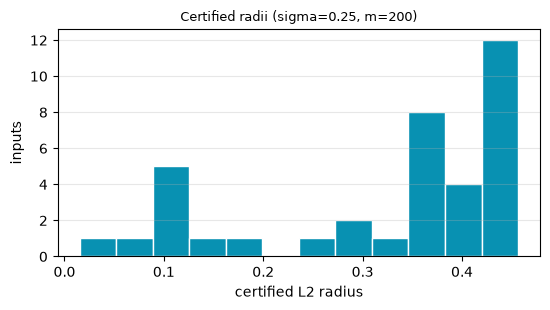

In [6]:
if radii:
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    ax.hist(radii, bins=12, color="#0891b2", edgecolor="white")
    ax.set_xlabel("certified L2 radius")
    ax.set_ylabel("inputs")
    ax.set_title(f"Certified radii (sigma={SIGMA}, m={M})", fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

**Expected output** — a histogram of radii. The spread matters: a defence that certifies a few inputs to a
large radius and most inputs to nearly zero is not uniformly useful, and the histogram shows that where a
single mean would hide it.

## Exercises

1. **Weaken the inner attack.** Retrain with `steps=1` inside adversarial training and evaluate with PGD-20.
   Report the gap. This is the "robust to the weak attack only" failure.
2. **Change sigma.** Run smoothing at σ = 0.12, 0.25 and 0.5. Plot certification rate and median radius.
   What is the trade?
3. **Attack the smoothed classifier.** Try PGD on $g$ with 200 samples per step and report whether any
   certified inputs change. What does the result tell you about the certificate's scope?
4. **Cost it.** Time one epoch of standard training and one of adversarial training, and compute the ratio.
   Write the sentence you would put in a design review.

## Reflection questions

1. Which defence would you deploy for a document-authentication model, and why is the answer not obvious?
2. A vendor claims "certified robustness". What three questions do you ask before believing the claim?
3. Adversarial training is empirical and smoothing is certified, yet smoothing protects a narrower class of
   attacks. How can both statements be true?

## References

1. Madry, A. et al., "Towards Deep Learning Models Resistant to Adversarial Attacks", ICLR 2018.
2. Cohen, J., Rosenfeld, E. and Kolter, J. Z., "Certified Adversarial Robustness via Randomized Smoothing", ICML 2019.
3. Zhang, H. et al., "Theoretically Principled Trade-off between Robustness and Accuracy", ICML 2019.
4. Athalye, A., Carlini, N. and Wagner, D., "Obfuscated Gradients Give a False Sense of Security", ICML 2018.